In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [ ]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

# This notebook contains example usage of the hot tail functions   #

## Distribution functions ##

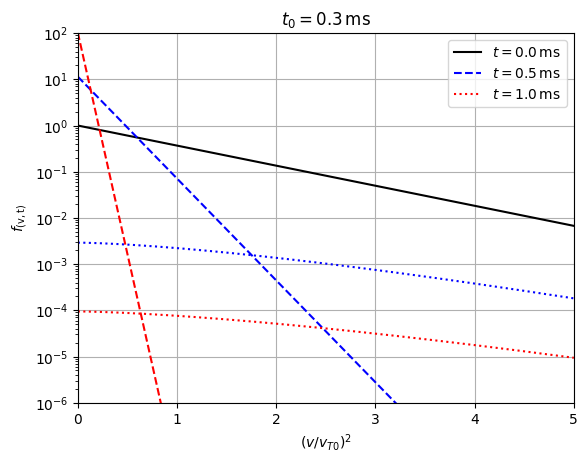

In [4]:
T0 = 3.1e3        # eV
Tf = 0.01*T0      # eV
t0 = 3e-4           # s
n0 = 2.8e19           # m^-3

tau = 0
vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s

x = np.linspace(0, 25, int(1e4))      # x = (v / vT0)^2
v = np.sqrt(x)*vT0
fm = getfm(v, n0, vT0)
norm_fac = max(fm)
#print(norm_fac)

plt.plot(x, fm/norm_fac, "k", label=rf"$t = {tau*1e3:.1f}\,\mathrm{{ms}}$")
plt.xlabel(r"$(v / v_{T0})^2$")
plt.yscale("log")
plt.ylim((1e-6, 1e2))
plt.xlim((0,5))
plt.ylabel(r"$f_{\mathrm{(v,t)}}$")
plt.title(r"$t_0 = 0.3\,\mathrm{ms}$")

plt.grid(True)

t = 5e-4
T = temperature(t, T0, Tf, t0)
vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
fm = getfm(v, n0, vT)
plt.plot(x, fm/norm_fac, "b--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
#plt.plot(x, f/norm_fac, "b:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")
plt.plot(x, f/norm_fac, "b:")

t = 1e-3
T = temperature(t, T0, Tf, t0)
vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
fm = getfm(v, n0, vT)
#plt.plot(x, fm/norm_fac, "r--", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")
plt.plot(x, fm/norm_fac, "r--")

nu0 = getnu0(n0, T0)
tau = getTau(nu0, t, t0)
f = getf(v, n0, vT0, tau)
plt.plot(x, f/norm_fac, "r:", label=rf"$t = {t*1e3:.1f}\,\mathrm{{ms}}$")
#xc = 6.742175302270628
#plt.axvline(xc, color='b', label=rf'$v_c \text{{ for }} t = 0.5\,\mathrm{{ms}}$')
#xc2 = 0.7439428396629868
#plt.axvline(xc2, color='r', label=rf'$v_c \text{{ for }} t = 1.0\,\mathrm{{ms}}$')

plt.legend()


## Hot tail density and rate ##

Text(0.5, 0, 't [ms]')

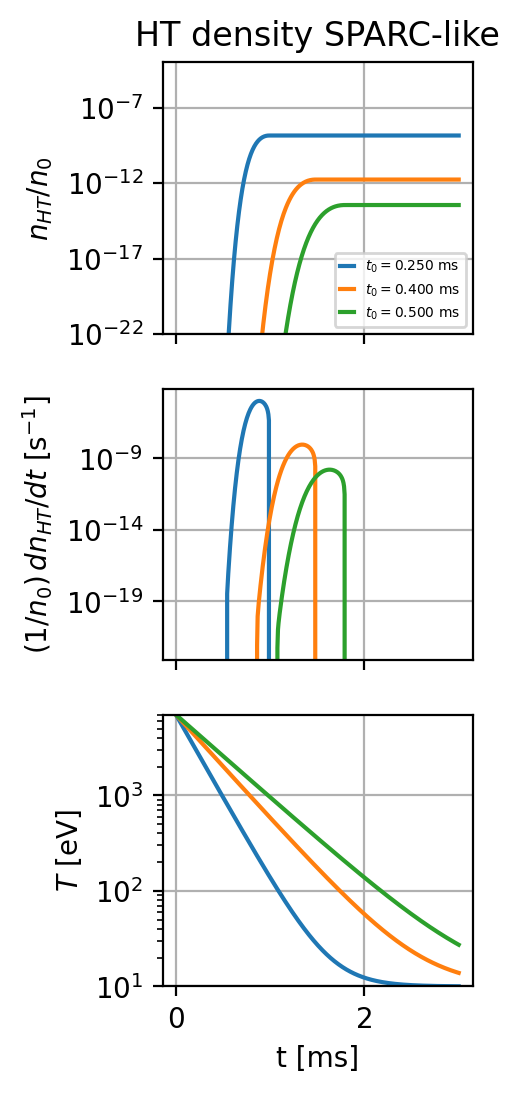

In [ ]:
# Constants
T0 = 7e3     # Initial temperature [eV]
Tf = 10 # Final temperature [eV]
#t0 = 0.5e-4    # s
t0_values = [0.25e-3, 0.4e-3, 0.5e-3] # Time delay(s) [s]
n0 = 3e20 # Electron density [m^-3]

Ip = 8.7e6 # Plasma current [A]
a = 0.57 # Minor radius [m]
k = 1.7 #elongation
j = Ip / (np.pi * a**2 * k) # current density [A/m^2]
eta = 0.51 * RE.getTransSpitzerResistivity(15,T0,1) * 0.01 # Resistivity [Ohm m]
E0 = eta * j # Electric field [V/m]

t = np.linspace(1e-5,3e-3,500) # Time array
nht = np.zeros_like(t) # Hot-tail density 
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(2,6), dpi=200)

for t0 in t0_values:

    nht = np.zeros_like(t) # Hot-tail density
    dnht_dt = np.zeros_like(t) #Hot tail rate

    for ii in range(1,t.shape[0]):
        T = temperature(t[ii], T0, Tf, t0) # eV
        nht[ii] = RE.getHT(n0,T0,E0,T,t[ii],t0)
        if (nht[ii] < nht[ii-1]): # had some numerical issues previously, safety just to make sure stay positive
            nht[ii] = nht[ii-1]

    dt = 1e-3 * t0
    dnht_dt = np.zeros_like(t)

    for ii in range(1, t.shape[0]-1):
        dnht_dt[ii] = RE.dHT_dt(
            n0=n0,
            T0=T0,
            Tf=Tf,
            E0=E0,
            t=t[ii],
            t0=t0,
            dt=dt
        )

        
        if dnht_dt[ii] < 0: # safety so no negatives
            dnht_dt[ii] = 0.0
    label = rf'$t_0={t0*1e3:.3f}$ ms'

    axs[0].plot(t*1e3, nht/n0, label=label)
    axs[1].plot(t*1e3, dnht_dt/n0, label=label)
    axs[2].plot(
        t*1e3,
        temperature(t, T0, Tf, t0),
        label=label
    )



# --- HT density ---
axs[0].set_title("HT density SPARC-like")
axs[0].set_ylabel(r'$n_{HT}/n_0$')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-22, 1e-4])
axs[0].grid()
#axs[0].legend()
axs[0].legend(fontsize=5, handlelength=1.0, markerscale=0.8)


# --- HT derivative ---
axs[1].set_ylabel(r'$(1/n_0)\,dn_{HT}/dt$ [s$^{-1}$]')
axs[1].set_yscale('log')
axs[1].grid()

# --- Temperature ---
axs[2].set_ylabel(r'$T$ [eV]')
axs[2].set_yscale('log')
axs[2].set_ylim([Tf, T0])
axs[2].grid()
axs[2].set_xlabel('t [ms]')

    


## Hot tail Current

C:\Users\grace\AppData\Local\Temp\ipykernel_1844\173552466.py:99: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


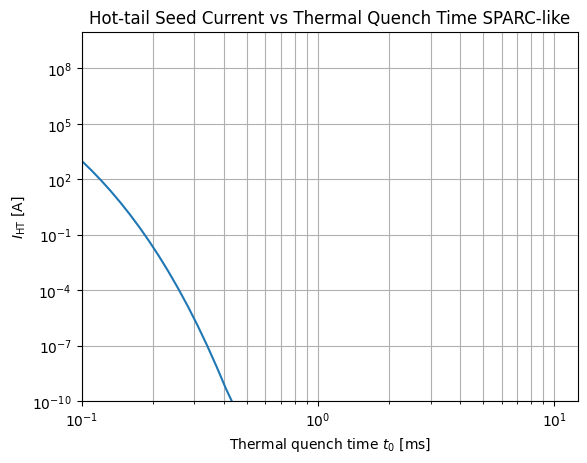

In [ ]:
#HT current vs TQ time 
# Plasma area
area = np.pi * a**2 * k


#TQ times [s]
t0_scan_sp = np.logspace(-4, -2, 50)   # 0.1 ms -> 10 ms

I_HT_sp = np.zeros_like(t0_scan_sp) # Hot tail currents

for i, t0 in enumerate(t0_scan_sp):

    # Make sure it's final value
    t_eval = 10 * t0

    n_ht = getHT(
        n0=n0,
        T0=T0,
        E0=E0,
        T=Tf,
        t=t_eval,
        t0=t0
    )

    # HT density to current
    I_HT_sp[i] = n_ht * const.e * const.c * area

#plt.figure(figsize=(5,4), dpi=200)

plt.loglog(t0_scan_sp*1e3, I_HT_sp)
plt.ylim((1e-10,1e10))
plt.xlim(left=1e-1)
plt.xlabel(r'Thermal quench time $t_0$ [ms]')
plt.ylabel(r'$I_{\rm HT}$ [A]')
plt.title('Hot-tail Seed Current vs Thermal Quench Time SPARC-like')
plt.grid(True, which='both')

plt.show()